<a href="https://colab.research.google.com/github/2025csmdsaadahmed/DAV_Lab_programs/blob/main/INDOFLOOD_ANALYTICS_DAES_Complete_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# INDOFLOOD ANALYTICS
## Exploratory Data Analysis of Indian Flood Events, Rainfall Patterns and Hydrological Impacts

**DAES Project | Google Colab Notebook**

This notebook analyses the INDOFLOODS data using Python. It combines flood-event records, rainfall variables and gauge-station metadata. The catchment-characteristics file is optional.

### Main objectives
1. Understand the dataset and its structure.
2. Clean and prepare the data.
3. Study flood duration, peak flood level, discharge and flood volume.
4. Explore rainfall measurements over 1–10 days and their relationship with flood characteristics.
5. Compare flood patterns across states, basins and flood types.
6. Apply descriptive statistics, visualisation, correlation, hypothesis testing, regression and clustering.

**Important:** This is an exploratory statistical study of historical events. It is not a real-time warning or operational flood-prediction system.

## Module 1 – Import libraries and load the datasets

Upload the three primary CSV files when prompted:
- `floodevents_indofloods.csv`
- `metadata_indofloods.csv`
- `precipitation_variables_indofloods.csv`

You may also upload `catchment_characteristics_indofloods.csv` for the optional extension.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from IPython.display import display
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid")
pd.set_option('display.max_columns', 120)
pd.set_option('display.max_rows', 100)

print("Libraries imported successfully.")

Libraries imported successfully.


In [ ]:
uploaded = files.upload()
print("Uploaded files:", list(uploaded.keys()))

In [4]:
from google.colab import files
import os

print("Please click 'Choose Files' below and select the following CSV files:")
print("- floodevents_indofloods.csv")
print("- metadata_indofloods.csv")
print("- precipitation_variables_indofloods.csv")
print("- catchment_characteristics_indofloods.csv (optional)")
print("\nWaiting for upload...")

uploaded = files.upload()

for fn in uploaded.keys():
    print(f'User uploaded file "{fn}" with length {len(uploaded[fn])} bytes')

Please click 'Choose Files' below and select the following CSV files:
- floodevents_indofloods.csv
- metadata_indofloods.csv
- precipitation_variables_indofloods.csv
- catchment_characteristics_indofloods.csv (optional)

Waiting for upload...


Saving catchment_characteristics_indofloods.csv to catchment_characteristics_indofloods.csv
Saving floodevents_indofloods.csv to floodevents_indofloods.csv
Saving metadata_indofloods.csv to metadata_indofloods.csv
Saving precipitation_variables_indofloods.csv to precipitation_variables_indofloods.csv
User uploaded file "catchment_characteristics_indofloods.csv" with length 146653 bytes
User uploaded file "floodevents_indofloods.csv" with length 469728 bytes
User uploaded file "metadata_indofloods.csv" with length 40058 bytes
User uploaded file "precipitation_variables_indofloods.csv" with length 677548 bytes


### Note on File Uploads
If you have already uploaded the files but they are in a different folder, make sure they are in the root `/content` directory or modify the paths below. Run the cell below to trigger the upload prompt if you haven't uploaded them yet.

In [5]:
# Read the uploaded CSV files by their expected filenames.
events_file = "floodevents_indofloods.csv"
metadata_file = "metadata_indofloods.csv"
rainfall_file = "precipitation_variables_indofloods.csv"
catchment_file = "catchment_characteristics_indofloods.csv"

events = pd.read_csv(events_file)
metadata = pd.read_csv(metadata_file)
rainfall = pd.read_csv(rainfall_file)

# Catchment characteristics are optional.
try:
    catchment = pd.read_csv(catchment_file)
    has_catchment = True
except FileNotFoundError:
    catchment = None
    has_catchment = False

print("Successfully loaded data!")
print("Flood events shape:", events.shape)
print("Metadata shape:", metadata.shape)
print("Rainfall shape:", rainfall.shape)
print("Catchment characteristics loaded:", has_catchment)

Successfully loaded data!
Flood events shape: (4548, 13)
Metadata shape: (214, 18)
Rainfall shape: (4548, 11)
Catchment characteristics loaded: True


## Module 2 – Dataset understanding and initial inspection

In [6]:
print("FLOOD EVENTS")
display(events.head())
print("\nMETADATA")
display(metadata.head())
print("\nRAINFALL VARIABLES")
display(rainfall.head())

if has_catchment:
    print("\nCATCHMENT CHARACTERISTICS")
    display(catchment.iloc[:5, :12])

FLOOD EVENTS


,EventID,Start Date,End Date,Peak Flood Level (m),Peak FL Date,Num Peak FL,Peak Discharge Q (cumec),Peak Discharge Date,Flood Volume (cumec),Event Duration (days),Time to Peak (days),Recession Time (day),Flood Type
0,INDOFLOODS-gauge-1010-1,2010-07-21,2010-07-21,47.95,2010-07-21,1,NaN,NaN,NaN,1,1,1,Flood
1,INDOFLOODS-gauge-1010-2,2016-07-23,2016-07-23,48.05,2016-07-23,1,NaN,NaN,NaN,1,1,1,Flood
2,INDOFLOODS-gauge-1010-3,2016-07-26,2016-07-26,48.00,2016-07-26,1,NaN,NaN,NaN,1,1,1,Flood
3,INDOFLOODS-gauge-1010-4,2017-08-11,2017-08-13,48.95,2017-08-12,1,NaN,NaN,NaN,3,2,2,Severe Flood
4,INDOFLOODS-gauge-1012-1,2010-07-21,2010-07-21,48.10,2010-07-21,1,NaN,NaN,NaN,1,1,1,Flood



METADATA


,GaugeID,Warning Level,Danger Level,Station,Latitude,Longitude,River Name/ Tributory/ SubTributory,Basin,State,Start_date,End_date,Level_Entries,Streamflow_Entries,Privacy,Source Catchment Area,Catchment Area,Area variation (%),Reliability
0,INDOFLOODS-gauge-394,259.20,262.00,Biligundulu,12.1800,77.7300,Cauvery,Cauvery,Karnataka,1971-08-30,2020-05-27,17715,17273,Open,36682.0,36889.800780,0.566493,Safe
1,INDOFLOODS-gauge-118,66.75,67.75,Jainagar,26.5833,86.1481,Ganga/Kosi/ Kamla-Balan,Ganga - Brahmaputra - Meghna/Barak,Bihar,1970-07-01,2010-12-31,14134,13725,Restricted,2131.0,2118.569336,0.583325,Safe
2,INDOFLOODS-gauge-119,49.00,50.00,Jhanjharpur,26.2333,86.2594,Ganga/Kosi/ Kamla-Balan,Ganga - Brahmaputra - Meghna/Barak,Bihar,1970-01-01,2010-12-31,14939,14616,Restricted,2945.0,3504.423584,18.995707,Safe
3,INDOFLOODS-gauge-121,70.00,71.00,DHENG BRIDGE,26.7228,85.3231,Ganga/Kosi/ Bagmati,Ganga - Brahmaputra - Meghna/Barak,Bihar,1970-07-01,2010-12-31,14762,14750,Restricted,3790.0,3580.846924,5.518551,Safe
4,INDOFLOODS-gauge-560,218.00,220.98,Burhanpur,21.2994,76.2350,Tapi,Tapi,Madhya Pradesh,1972-09-14,2019-08-20,16611,16249,Open,8487.0,8926.981445,5.184181,Safe



RAINFALL VARIABLES


,EventID,T1d,T2d,T3d,T4d,T5d,T6d,T7d,T8d,T9d,T10d
0,INDOFLOODS-gauge-1010-1,32.833274,65.228899,99.413481,124.272676,133.344557,138.143367,140.458797,155.228323,177.372062,203.686949
1,INDOFLOODS-gauge-1010-2,27.011286,60.147585,86.528438,111.753411,136.083522,158.516418,197.476361,216.301547,243.307830,247.079665
2,INDOFLOODS-gauge-1010-3,50.413312,82.466743,124.859376,151.870662,185.006961,211.387814,236.612787,260.942897,283.375793,322.335737
3,INDOFLOODS-gauge-1010-4,46.282306,86.765681,104.849158,115.481116,125.934658,130.959363,134.251184,148.829043,167.936433,182.415493
4,INDOFLOODS-gauge-1012-1,86.018135,137.676182,176.841432,203.447235,215.046211,225.184558,239.477965,284.881663,411.163733,522.828973



CATCHMENT CHARACTERISTICS


,GaugeID,Stream Order,Maximal Flow Length,Downvalley Length,Drainage Area,Catchment Relief,Catchment Length,Catchment Perimeter,Sinuosity Index,Form Factor,Relief Ratio,Elongation Ratio
0,INDOFLOODS-gauge-1013,4,141541.1719,113605.7734,3542.106445,4416,116870.2188,3.152483e+05,1.245898,0.259331,0.037786,5.100000e-10
1,INDOFLOODS-gauge-1018,5,277715.5938,183743.9063,9908.034180,7735,201079.8125,6.079071e+05,1.511428,0.245048,0.038467,1.770000e-10
2,INDOFLOODS-gauge-1020,5,463678.7188,330162.8125,21904.482420,1204,341410.3438,1.098149e+06,1.404394,0.187923,0.003527,7.020000e-11
3,INDOFLOODS-gauge-1042,4,141541.1719,113605.7734,3542.106445,4416,116870.2188,3.152483e+05,1.245898,0.259331,0.037786,5.100000e-10
4,INDOFLOODS-gauge-1050,4,218563.5625,170715.4063,4924.346191,6466,175772.3281,5.030641e+05,1.280280,0.159385,0.036786,2.870000e-10


In [7]:
def dataset_overview(df, name):
    print(f"--- {name} ---")
    print("Rows and columns:", df.shape)
    print("\nData types:")
    display(df.dtypes.astype(str).to_frame("Data Type"))
    print("\nMissing values:")
    display(df.isna().sum().to_frame("Missing Values"))
    print("\nDuplicate rows:", df.duplicated().sum())

dataset_overview(events, "Flood events")
dataset_overview(metadata, "Gauge metadata")
dataset_overview(rainfall, "Precipitation variables")

--- Flood events ---
Rows and columns: (4548, 13)

Data types:


,Data Type
EventID,object
Start Date,object
End Date,object
Peak Flood Level (m),float64
Peak FL Date,object
Num Peak FL,int64
Peak Discharge Q (cumec),float64
Peak Discharge Date,object
Flood Volume (cumec),float64
Event Duration (days),int64



Missing values:


,Missing Values
EventID,0
Start Date,0
End Date,0
Peak Flood Level (m),0
Peak FL Date,0
Num Peak FL,0
Peak Discharge Q (cumec),555
Peak Discharge Date,555
Flood Volume (cumec),577
Event Duration (days),0



Duplicate rows: 0
--- Gauge metadata ---
Rows and columns: (214, 18)

Data types:


,Data Type
GaugeID,object
Warning Level,float64
Danger Level,float64
Station,object
Latitude,float64
Longitude,float64
River Name/ Tributory/ SubTributory,object
Basin,object
State,object
Start_date,object


... (3 outputs left out)

,Data Type
EventID,object
T1d,float64
T2d,float64
T3d,float64
T4d,float64
T5d,float64
T6d,float64
T7d,float64
T8d,float64
T9d,float64



Missing values:


,Missing Values
EventID,0
T1d,0
T2d,0
T3d,0
T4d,0
T5d,0
T6d,0
T7d,0
T8d,0
T9d,0



Duplicate rows: 0


In [8]:
print("Flood type counts:")
display(events["Flood Type"].value_counts(dropna=False).to_frame("Number of events"))

print("Unique event IDs:", events["EventID"].nunique())
print("Unique gauge stations:", metadata["GaugeID"].nunique())
print("Rainfall rows:", rainfall["EventID"].nunique())

Flood type counts:


,Number of events
Flood Type,
Flood,2919
Severe Flood,1629


Unique event IDs: 4548
Unique gauge stations: 214
Rainfall rows: 4548


## Module 3 – Data cleaning and preparation

The event identifier contains the gauge identifier followed by an event number. We derive `GaugeID` from `EventID` so event records can be connected to station metadata.

We retain missing values in the original columns and do not replace unknown discharge or volume values with zero. Dates and numerical columns are converted to suitable types.

In [9]:
# Work on copies so the original loaded tables remain unchanged.
events_clean = events.copy()
metadata_clean = metadata.copy()
rainfall_clean = rainfall.copy()

# Convert date fields.
for col in ["Start Date", "End Date", "Peak FL Date", "Peak Discharge Date"]:
    events_clean[col] = pd.to_datetime(events_clean[col], errors="coerce")

for col in ["Start_date", "End_date"]:
    metadata_clean[col] = pd.to_datetime(metadata_clean[col], errors="coerce")

# Derive GaugeID from EventID, e.g. INDOFLOODS-gauge-1010-1
events_clean["GaugeID"] = events_clean["EventID"].astype(str).str.rsplit("-", n=1).str[0]

# Convert expected measurement columns to numeric.
event_numeric = [
    "Peak Flood Level (m)", "Num Peak FL", "Peak Discharge Q (cumec)",
    "Flood Volume (cumec)", "Event Duration (days)",
    "Time to Peak (days)", "Recession Time (day)"
]
for col in event_numeric:
    events_clean[col] = pd.to_numeric(events_clean[col], errors="coerce")

rain_cols = [f"T{i}d" for i in range(1, 11)]
for col in rain_cols:
    rainfall_clean[col] = pd.to_numeric(rainfall_clean[col], errors="coerce")

# Remove exact duplicate rows, if any.
events_clean = events_clean.drop_duplicates()
metadata_clean = metadata_clean.drop_duplicates(subset="GaugeID")
rainfall_clean = rainfall_clean.drop_duplicates(subset="EventID")

print("Cleaned shapes:")
print(events_clean.shape, metadata_clean.shape, rainfall_clean.shape)
print("Invalid/missing event start dates:", events_clean["Start Date"].isna().sum())

Cleaned shapes:
(4548, 14) (214, 18) (4548, 11)
Invalid/missing event start dates: 0


In [10]:
# Check whether keys are unique and whether event IDs match across tables.
print("Duplicate EventID in events:", events_clean["EventID"].duplicated().sum())
print("Duplicate EventID in rainfall:", rainfall_clean["EventID"].duplicated().sum())

event_ids = set(events_clean["EventID"])
rain_ids = set(rainfall_clean["EventID"])
gauge_ids = set(metadata_clean["GaugeID"])
event_gauges = set(events_clean["GaugeID"])

print("Event IDs without rainfall row:", len(event_ids - rain_ids))
print("Event gauge IDs without metadata:", len(event_gauges - gauge_ids))

Duplicate EventID in events: 0
Duplicate EventID in rainfall: 0
Event IDs without rainfall row: 0
Event gauge IDs without metadata: 0


In [11]:
# Merge event-level flood information with event-level rainfall, then station metadata.
analysis = events_clean.merge(
    rainfall_clean,
    on="EventID",
    how="left",
    validate="one_to_one"
)

analysis = analysis.merge(
    metadata_clean,
    on="GaugeID",
    how="left",
    suffixes=("", "_station"),
    validate="many_to_one"
)

print("Combined analysis dataset:", analysis.shape)
display(analysis.head())
print("Rows without matched station metadata:", analysis["Station"].isna().sum())

Combined analysis dataset: (4548, 41)


,EventID,Start Date,End Date,Peak Flood Level (m),Peak FL Date,Num Peak FL,Peak Discharge Q (cumec),Peak Discharge Date,Flood Volume (cumec),Event Duration (days),Time to Peak (days),Recession Time (day),Flood Type,GaugeID,T1d,T2d,T3d,T4d,T5d,T6d,T7d,T8d,T9d,T10d,Warning Level,Danger Level,Station,Latitude,Longitude,River Name/ Tributory/ SubTributory,Basin,State,Start_date,End_date,Level_Entries,Streamflow_Entries,Privacy,Source Catchment Area,Catchment Area,Area variation (%),Reliability
0,INDOFLOODS-gauge-1010-1,2010-07-21,2010-07-21,47.95,2010-07-21,1,NaN,NaT,NaN,1,1,1,Flood,INDOFLOODS-gauge-1010,32.833274,65.228899,99.413481,124.272676,133.344557,138.143367,140.458797,155.228323,177.372062,203.686949,47.81,48.42,L.R.P. Crossing,26.46,89.86,sankosh,NaN,West Bengal,2010-06-01,2020-10-31,1312,0,Open,NaN,10008.260740,NaN,Caution
1,INDOFLOODS-gauge-1010-2,2016-07-23,2016-07-23,48.05,2016-07-23,1,NaN,NaT,NaN,1,1,1,Flood,INDOFLOODS-gauge-1010,27.011286,60.147585,86.528438,111.753411,136.083522,158.516418,197.476361,216.301547,243.307830,247.079665,47.81,48.42,L.R.P. Crossing,26.46,89.86,sankosh,NaN,West Bengal,2010-06-01,2020-10-31,1312,0,Open,NaN,10008.260740,NaN,Caution
2,INDOFLOODS-gauge-1010-3,2016-07-26,2016-07-26,48.00,2016-07-26,1,NaN,NaT,NaN,1,1,1,Flood,INDOFLOODS-gauge-1010,50.413312,82.466743,124.859376,151.870662,185.006961,211.387814,236.612787,260.942897,283.375793,322.335737,47.81,48.42,L.R.P. Crossing,26.46,89.86,sankosh,NaN,West Bengal,2010-06-01,2020-10-31,1312,0,Open,NaN,10008.260740,NaN,Caution
3,INDOFLOODS-gauge-1010-4,2017-08-11,2017-08-13,48.95,2017-08-12,1,NaN,NaT,NaN,3,2,2,Severe Flood,INDOFLOODS-gauge-1010,46.282306,86.765681,104.849158,115.481116,125.934658,130.959363,134.251184,148.829043,167.936433,182.415493,47.81,48.42,L.R.P. Crossing,26.46,89.86,sankosh,NaN,West Bengal,2010-06-01,2020-10-31,1312,0,Open,NaN,10008.260740,NaN,Caution
4,INDOFLOODS-gauge-1012-1,2010-07-21,2010-07-21,48.10,2010-07-21,1,NaN,NaT,NaN,1,1,1,Flood,INDOFLOODS-gauge-1012,86.018135,137.676182,176.841432,203.447235,215.046211,225.184558,239.477965,284.881663,411.163733,522.828973,47.81,48.42,L.R.P. Crossing,26.47,89.79,raidak-ii,NaN,West Bengal,2010-06-01,2020-10-31,1167,0,Open,NaN,148.798309,NaN,Caution


Rows without matched station metadata: 0


In [12]:
# Add useful time-derived fields.
analysis["Start Year"] = analysis["Start Date"].dt.year
analysis["Start Month"] = analysis["Start Date"].dt.month
analysis["Start Month Name"] = analysis["Start Date"].dt.month_name()
analysis["Start Season"] = analysis["Start Month"].map({
    12: "Winter", 1: "Winter", 2: "Winter",
    3: "Pre-monsoon", 4: "Pre-monsoon", 5: "Pre-monsoon",
    6: "Monsoon", 7: "Monsoon", 8: "Monsoon", 9: "Monsoon",
    10: "Post-monsoon", 11: "Post-monsoon"
})

# Average rainfall accumulation values across the available 1–10 day windows.
analysis["Mean Rainfall T1-T10"] = analysis[rain_cols].mean(axis=1)
analysis["Rainfall T10"] = analysis["T10d"]

display(analysis[["EventID", "GaugeID", "Start Date", "State", "Basin",
                  "Peak Flood Level (m)", "Event Duration (days)",
                  "T1d", "T10d", "Mean Rainfall T1-T10"]].head())

,EventID,GaugeID,Start Date,State,Basin,Peak Flood Level (m),Event Duration (days),T1d,T10d,Mean Rainfall T1-T10
0,INDOFLOODS-gauge-1010-1,INDOFLOODS-gauge-1010,2010-07-21,West Bengal,NaN,47.95,1,32.833274,203.686949,126.998239
1,INDOFLOODS-gauge-1010-2,INDOFLOODS-gauge-1010,2016-07-23,West Bengal,NaN,48.05,1,27.011286,247.079665,148.420606
2,INDOFLOODS-gauge-1010-3,INDOFLOODS-gauge-1010,2016-07-26,West Bengal,NaN,48.00,1,50.413312,322.335737,190.927208
3,INDOFLOODS-gauge-1010-4,INDOFLOODS-gauge-1010,2017-08-11,West Bengal,NaN,48.95,3,46.282306,182.415493,124.370444
4,INDOFLOODS-gauge-1012-1,INDOFLOODS-gauge-1012,2010-07-21,West Bengal,NaN,48.10,1,86.018135,522.828973,250.256609


## Module 4 – Descriptive statistics and exploratory data analysis

In [14]:
numeric_summary_cols = [
    "Peak Flood Level (m)", "Peak Discharge Q (cumec)", "Flood Volume (cumec)",
    "Event Duration (days)", "Time to Peak (days)", "Recession Time (day)",
    "Mean Rainfall T1-T10"
]
display(analysis[numeric_summary_cols].describe().T)

,count,mean,std,min,25%,50%,75%,max
Peak Flood Level (m),4548.0,220.163527,221.493764,2.53,15.997500,222.195000,311.342500,4.485000e+03
Peak Discharge Q (cumec),3993.0,2445.574793,4257.918733,0.00,488.600000,1175.000000,2658.000000,7.961882e+04
Flood Volume (cumec),3971.0,8060.504827,51045.460038,0.22,746.685000,2207.300000,6245.000000,2.870215e+06
Event Duration (days),4548.0,10.357960,180.963017,1.00,1.000000,2.000000,4.000000,1.114700e+04
Time to Peak (days),4548.0,4.181618,46.338885,1.00,1.000000,1.000000,2.000000,1.900000e+03
Recession Time (day),4548.0,7.176341,146.036357,1.00,1.000000,2.000000,3.000000,9.357000e+03
Mean Rainfall T1-T10,4548.0,140.986007,139.845187,0.00,49.275923,100.647604,184.990831,1.214714e+03


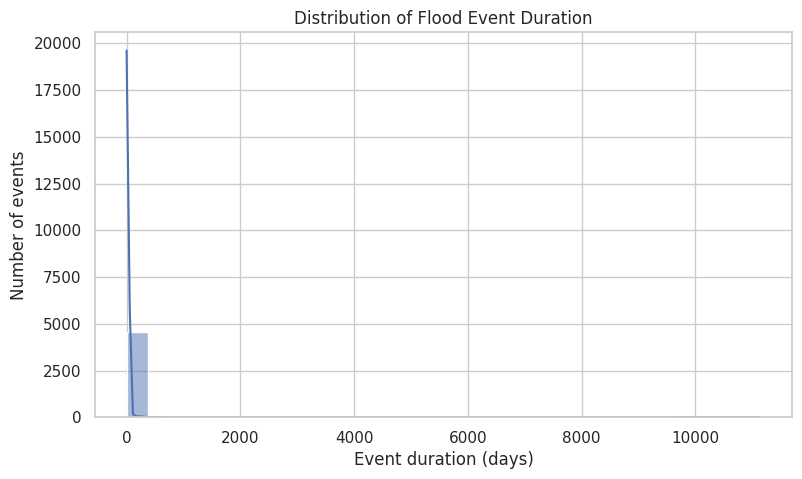

In [13]:
# Distribution of flood event duration
plt.figure(figsize=(9, 5))
sns.histplot(data=analysis, x="Event Duration (days)", bins=30, kde=True)
plt.title("Distribution of Flood Event Duration")
plt.xlabel("Event duration (days)")
plt.ylabel("Number of events")
plt.show()

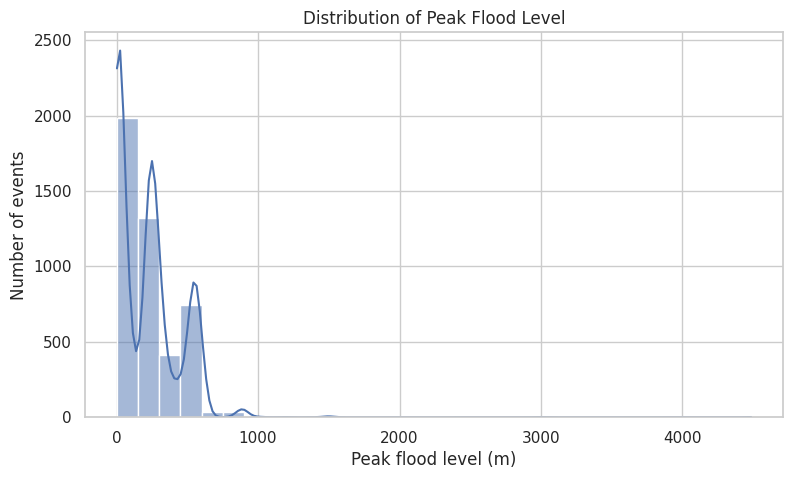

In [15]:
# Distribution of peak flood level
plt.figure(figsize=(9, 5))
sns.histplot(data=analysis, x="Peak Flood Level (m)", bins=30, kde=True)
plt.title("Distribution of Peak Flood Level")
plt.xlabel("Peak flood level (m)")
plt.ylabel("Number of events")
plt.show()

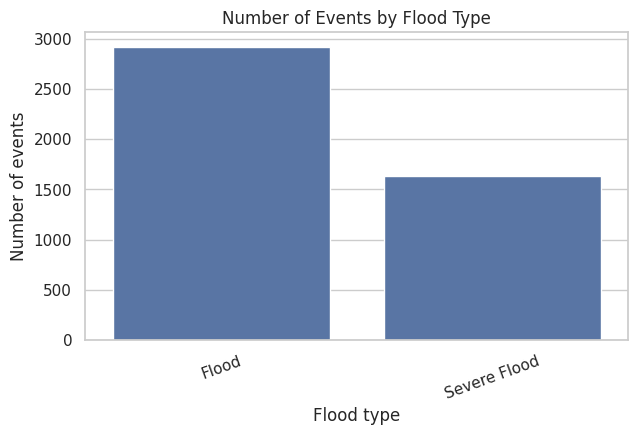

In [16]:
# Flood type frequency
plt.figure(figsize=(7, 4))
order = analysis["Flood Type"].value_counts().index
sns.countplot(data=analysis, x="Flood Type", order=order)
plt.title("Number of Events by Flood Type")
plt.xlabel("Flood type")
plt.ylabel("Number of events")
plt.xticks(rotation=20)
plt.show()

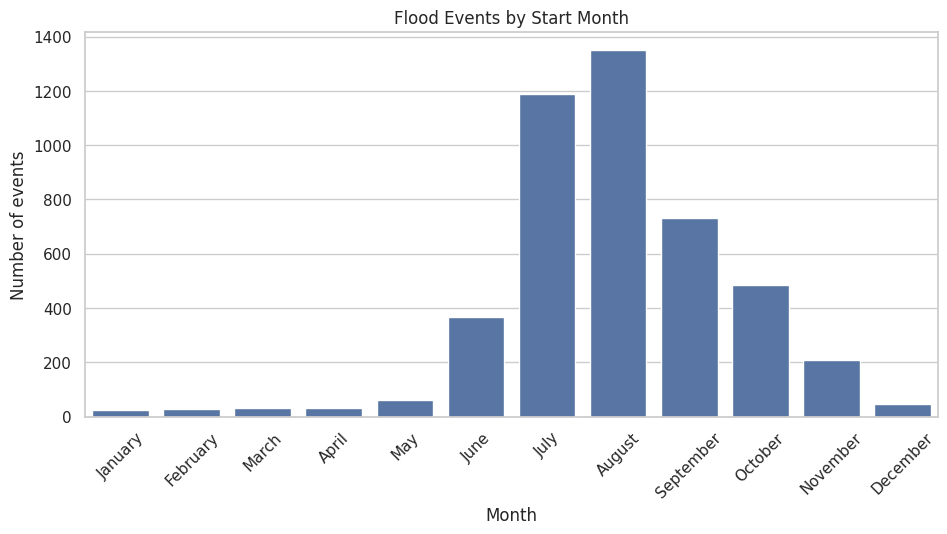

In [17]:
# Monthly distribution of event starts
monthly_counts = analysis["Start Month Name"].value_counts()
month_order = ["January", "February", "March", "April", "May", "June",
               "July", "August", "September", "October", "November", "December"]
monthly_counts = monthly_counts.reindex(month_order).dropna()

plt.figure(figsize=(11, 5))
sns.barplot(x=monthly_counts.index, y=monthly_counts.values)
plt.title("Flood Events by Start Month")
plt.xlabel("Month")
plt.ylabel("Number of events")
plt.xticks(rotation=45)
plt.show()

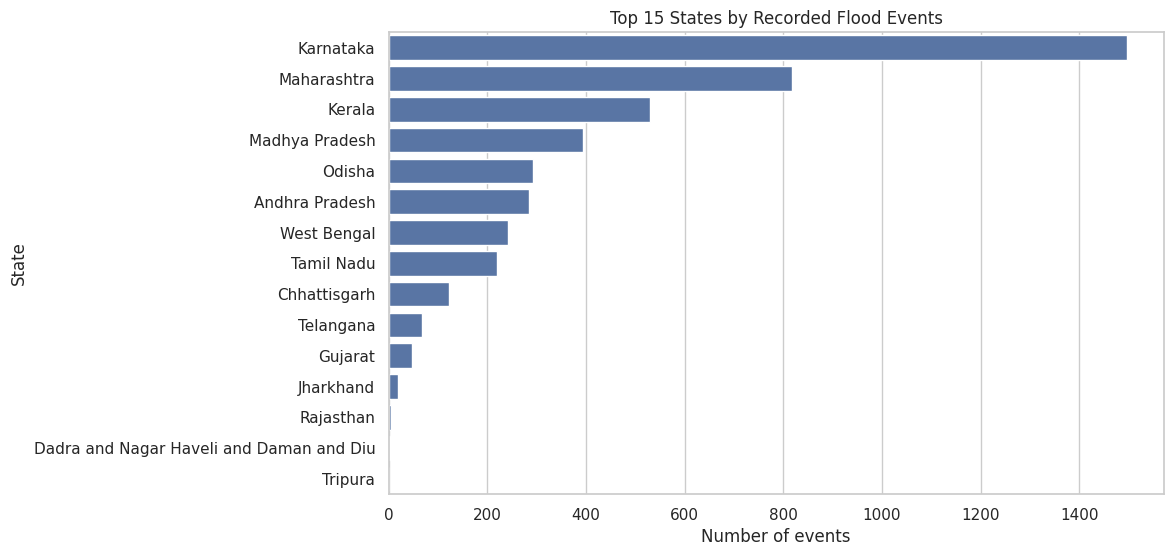

In [18]:
# Events by state: top 15 states by event count
state_counts = analysis["State"].fillna("Unknown").value_counts().head(15)

plt.figure(figsize=(10, 6))
sns.barplot(x=state_counts.values, y=state_counts.index)
plt.title("Top 15 States by Recorded Flood Events")
plt.xlabel("Number of events")
plt.ylabel("State")
plt.show()

,Average Peak Flood Level (m)
Flood Type,
Severe Flood,268.163801
Flood,193.376119


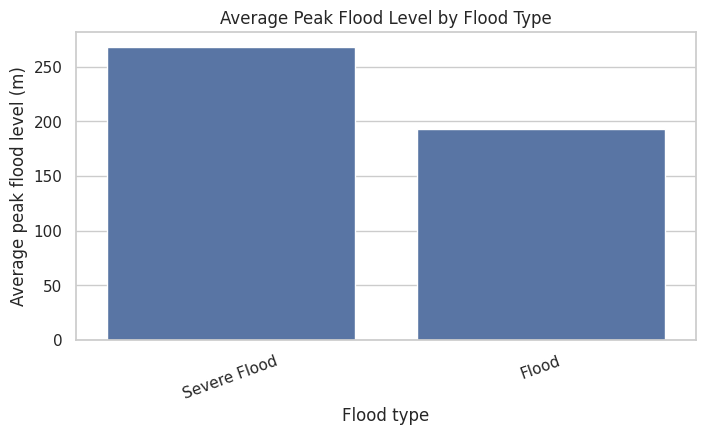

In [19]:
# Mean peak flood level by flood type
type_level = analysis.groupby("Flood Type", dropna=False)["Peak Flood Level (m)"].mean().sort_values(ascending=False)
display(type_level.to_frame("Average Peak Flood Level (m)"))

plt.figure(figsize=(8, 4))
sns.barplot(x=type_level.index.astype(str), y=type_level.values)
plt.title("Average Peak Flood Level by Flood Type")
plt.xlabel("Flood type")
plt.ylabel("Average peak flood level (m)")
plt.xticks(rotation=20)
plt.show()

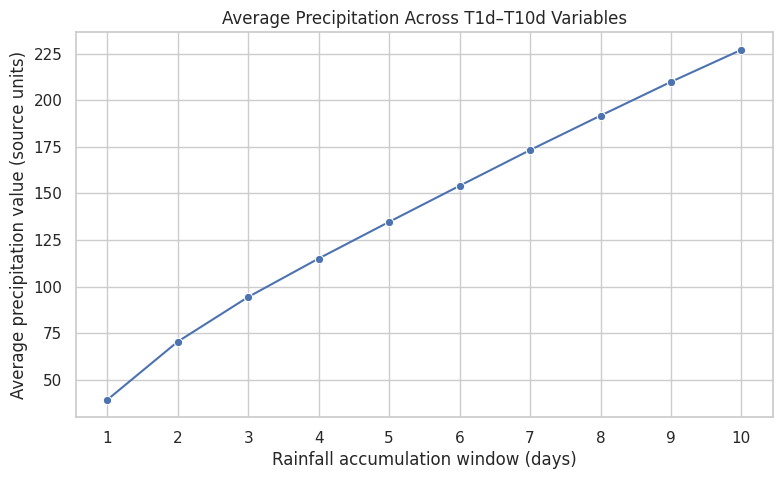

,Mean precipitation value
T1d,39.299847
T2d,70.489588
T3d,94.427949
T4d,115.064379
T5d,134.716612
T6d,154.063244
T7d,173.230736
T8d,191.697737
T9d,209.826395
T10d,227.043580


In [20]:
# Rainfall accumulation windows: compare average values for T1d to T10d.
rain_means = analysis[rain_cols].mean()

plt.figure(figsize=(9, 5))
sns.lineplot(x=[1,2,3,4,5,6,7,8,9,10], y=rain_means.values, marker="o")
plt.title("Average Precipitation Across T1d–T10d Variables")
plt.xlabel("Rainfall accumulation window (days)")
plt.ylabel("Average precipitation value (source units)")
plt.xticks(range(1, 11))
plt.show()

display(rain_means.to_frame("Mean precipitation value"))

## Module 5 – Relationship analysis, statistical testing and modelling

The following analyses are exploratory. Rainfall variables are cumulative windows (T1d–T10d); their exact interpretation and units should be confirmed using the dataset documentation before making physical conclusions.

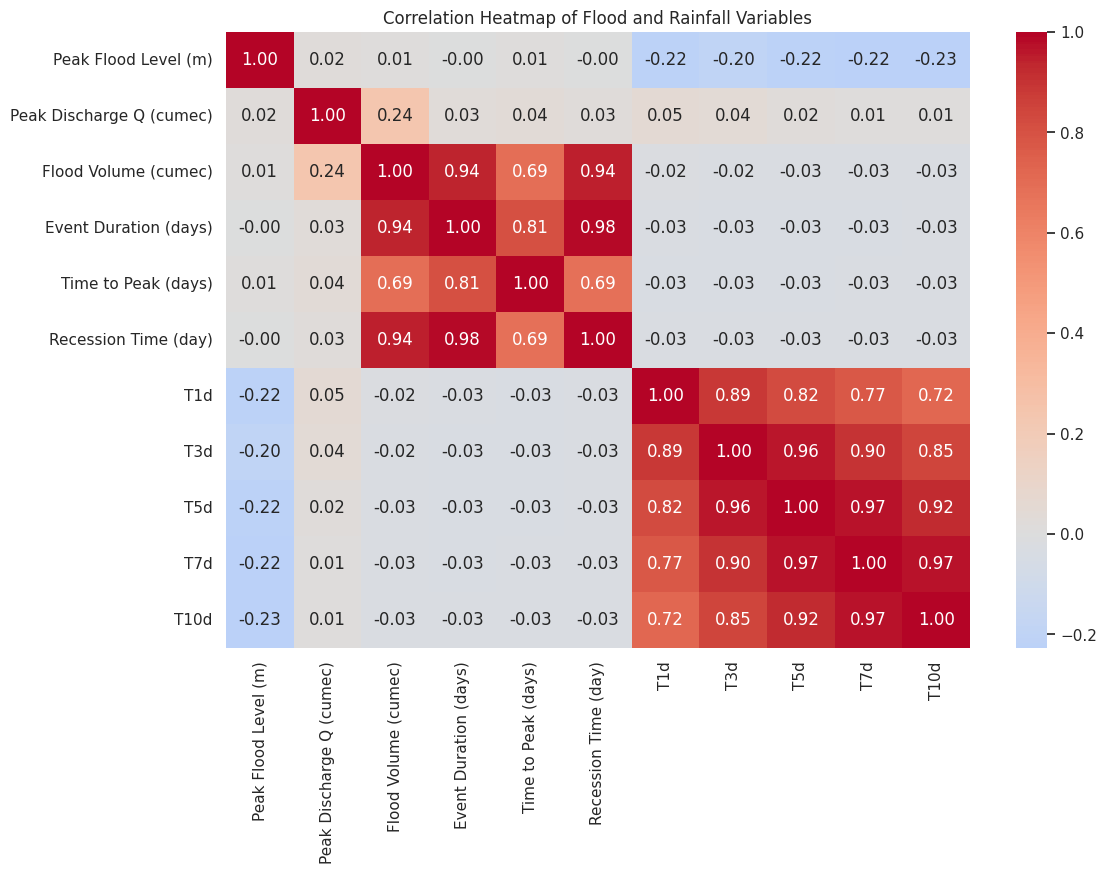

In [21]:
# Correlation among selected numerical variables.
corr_cols = [
    "Peak Flood Level (m)", "Peak Discharge Q (cumec)", "Flood Volume (cumec)",
    "Event Duration (days)", "Time to Peak (days)", "Recession Time (day)",
    "T1d", "T3d", "T5d", "T7d", "T10d"
]
corr = analysis[corr_cols].corr(numeric_only=True)

plt.figure(figsize=(12, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap of Flood and Rainfall Variables")
plt.show()

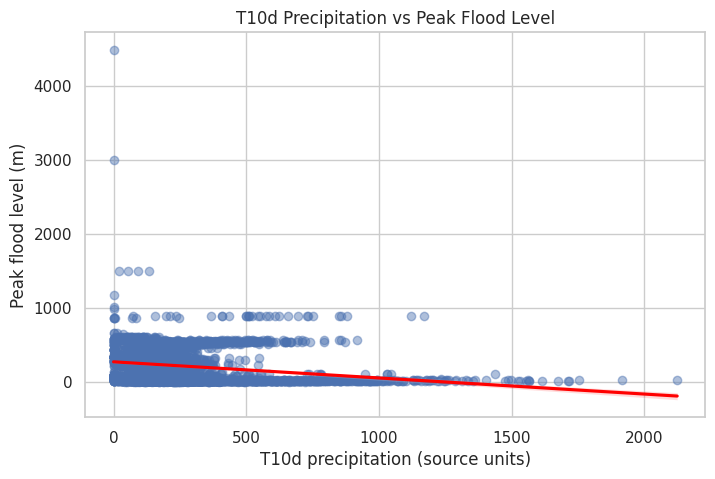

Number of complete observations: 4548


In [22]:
# Scatter plot: T10d rainfall against peak flood level.
scatter_data = analysis[["T10d", "Peak Flood Level (m)"]].dropna()

plt.figure(figsize=(8, 5))
sns.regplot(data=scatter_data, x="T10d", y="Peak Flood Level (m)",
            scatter_kws={"alpha": 0.45}, line_kws={"color": "red"})
plt.title("T10d Precipitation vs Peak Flood Level")
plt.xlabel("T10d precipitation (source units)")
plt.ylabel("Peak flood level (m)")
plt.show()

print("Number of complete observations:", len(scatter_data))

In [23]:
# Hypothesis test: compare event duration between flood types.
# This uses the two most frequent flood types when exactly two groups are available.
from scipy.stats import ttest_ind, mannwhitneyu

type_counts = analysis["Flood Type"].value_counts()
print(type_counts)

if len(type_counts) >= 2:
    selected_types = type_counts.index[:2].tolist()
    group1 = analysis.loc[analysis["Flood Type"] == selected_types[0],
                          "Event Duration (days)"].dropna()
    group2 = analysis.loc[analysis["Flood Type"] == selected_types[1],
                          "Event Duration (days)"].dropna()

    print("Groups:", selected_types)
    print("Sample sizes:", len(group1), len(group2))
    if len(group1) > 1 and len(group2) > 1:
        t_stat, p_value = ttest_ind(group1, group2, equal_var=False)
        print(f"Welch t-test statistic: {t_stat:.4f}")
        print(f"P-value: {p_value:.6f}")
        if p_value < 0.05:
            print("Result: Evidence of a difference in mean event duration at the 5% significance level.")
        else:
            print("Result: Insufficient evidence of a difference in mean event duration at the 5% significance level.")
else:
    print("Not enough flood-type groups for a two-group comparison.")

Flood Type
Flood           2919
Severe Flood    1629
Name: count, dtype: int64
Groups: ['Flood', 'Severe Flood']
Sample sizes: 2919 1629
Welch t-test statistic: -2.8618
P-value: 0.004266
Result: Evidence of a difference in mean event duration at the 5% significance level.


Intercept: 271.82410924843055
Coefficient for T10d: -0.21633263449776935
MAE: 155.87326861232762
RMSE: 201.41508263905038
R-squared: 0.05820636051816497


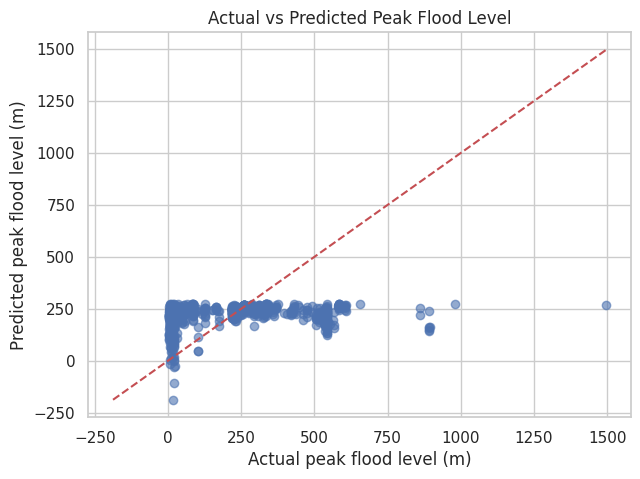

In [24]:
# Simple exploratory linear regression: predict peak flood level from T10d precipitation.
# This is a relationship model, not an operational flood forecasting model.
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

model_data = analysis[["T10d", "Peak Flood Level (m)"]].dropna()

if len(model_data) >= 20:
    X = model_data[["T10d"]]
    y = model_data["Peak Flood Level (m)"]

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )

    regression_model = LinearRegression()
    regression_model.fit(X_train, y_train)
    predictions = regression_model.predict(X_test)

    print("Intercept:", regression_model.intercept_)
    print("Coefficient for T10d:", regression_model.coef_[0])
    print("MAE:", mean_absolute_error(y_test, predictions))
    print("RMSE:", np.sqrt(mean_squared_error(y_test, predictions)))
    print("R-squared:", r2_score(y_test, predictions))

    plt.figure(figsize=(7, 5))
    plt.scatter(y_test, predictions, alpha=0.6)
    low = min(y_test.min(), predictions.min())
    high = max(y_test.max(), predictions.max())
    plt.plot([low, high], [low, high], "r--")
    plt.title("Actual vs Predicted Peak Flood Level")
    plt.xlabel("Actual peak flood level (m)")
    plt.ylabel("Predicted peak flood level (m)")
    plt.show()
else:
    print("Not enough complete rows for the regression example.")

Cluster sizes:


,Number of events
Cluster,
0,2561
1,3
2,1984


Cluster profiles (means in original units):


,Peak Flood Level (m),Event Duration (days),Time to Peak (days),T10d
Cluster,,,,
0,367.393350,9.623585,4.021476,144.701752
1,177.646667,5145.666667,1608.666667,265.812099
2,30.179643,3.540827,1.962198,333.273981


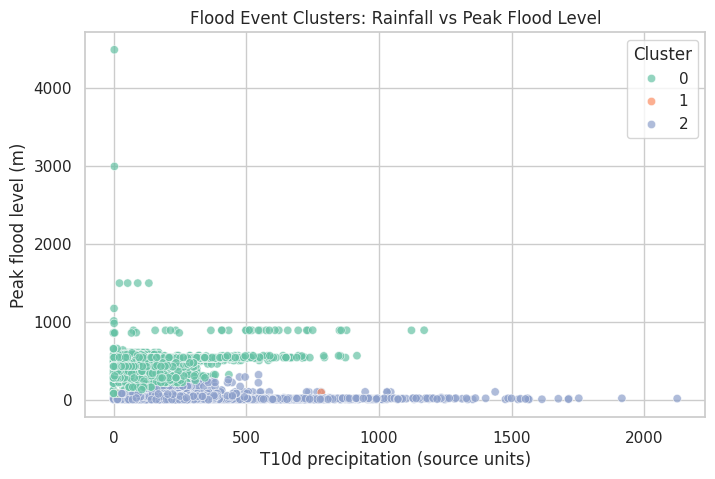

In [25]:
# K-Means clustering of flood events using selected numerical characteristics.
# Standardisation is important because variables use different units.
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

cluster_features = [
    "Peak Flood Level (m)", "Event Duration (days)",
    "Time to Peak (days)", "T10d"
]
cluster_data = analysis[cluster_features].dropna().copy()

if len(cluster_data) >= 10:
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(cluster_data)

    kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
    cluster_data["Cluster"] = kmeans.fit_predict(X_scaled)

    analysis["Cluster"] = np.nan
    analysis.loc[cluster_data.index, "Cluster"] = cluster_data["Cluster"]

    print("Cluster sizes:")
    display(cluster_data["Cluster"].value_counts().sort_index().to_frame("Number of events"))

    print("Cluster profiles (means in original units):")
    display(cluster_data.groupby("Cluster")[cluster_features].mean())

    plt.figure(figsize=(8, 5))
    sns.scatterplot(data=cluster_data, x="T10d", y="Peak Flood Level (m)",
                    hue="Cluster", palette="Set2", alpha=0.7)
    plt.title("Flood Event Clusters: Rainfall vs Peak Flood Level")
    plt.xlabel("T10d precipitation (source units)")
    plt.ylabel("Peak flood level (m)")
    plt.show()
else:
    print("Not enough complete rows for clustering.")

## Optional extension – Add catchment characteristics

The catchment file contains 155 gauge records and 108 variables. It has many missing values in higher-order stream measurements. For a clear introductory DAES submission, this section is optional.

The merge uses `GaugeID`; unmatched gauges remain missing rather than being discarded.

Extended dataset shape: (4548, 155)
Rows with catchment match: 4548


,count,mean,std,min,25%,50%,75%,max
Drainage Area,4548.0,16937.286737,23830.459667,24.711016,1797.186646,8031.312988,35499.886720,305683.812500
Catchment Relief,4548.0,1313.834213,1222.829918,4.000000,791.000000,1050.000000,1482.000000,7735.000000
Drainage Density,4548.0,0.000158,0.000012,0.000073,0.000154,0.000159,0.000164,0.000192
Annual Precipitation,4548.0,1809.300118,1200.972153,588.617322,1094.228818,1286.532200,2200.758763,6177.069164
Population Density,4548.0,340.796395,231.734461,20.618854,200.931692,288.356943,430.380223,1913.898914


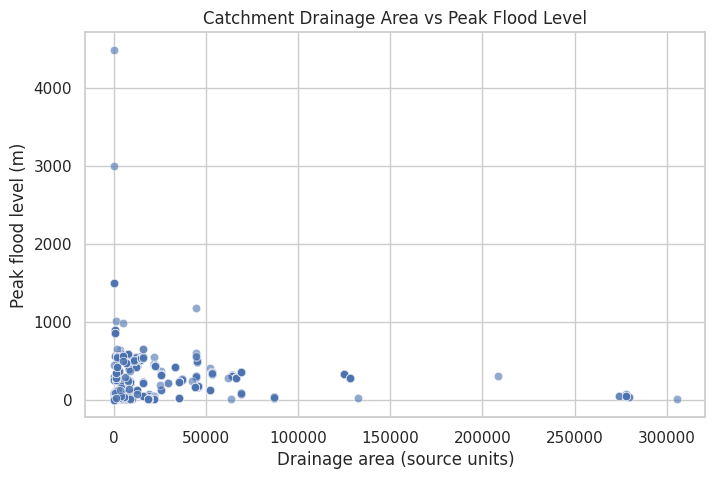

In [26]:
if has_catchment:
    catchment_clean = catchment.drop_duplicates(subset="GaugeID").copy()
    extended = analysis.merge(
        catchment_clean,
        on="GaugeID",
        how="left",
        suffixes=("", "_catchment"),
        validate="many_to_one"
    )
    print("Extended dataset shape:", extended.shape)
    print("Rows with catchment match:", extended["Drainage Area"].notna().sum())

    optional_cols = ["Drainage Area", "Catchment Relief", "Drainage Density",
                     "Annual Precipitation", "Population Density"]
    available_optional = [c for c in optional_cols if c in extended.columns]
    display(extended[available_optional].describe().T)

    if "Drainage Area" in extended.columns:
        plt.figure(figsize=(8, 5))
        sns.scatterplot(data=extended, x="Drainage Area",
                        y="Peak Flood Level (m)", alpha=0.6)
        plt.title("Catchment Drainage Area vs Peak Flood Level")
        plt.xlabel("Drainage area (source units)")
        plt.ylabel("Peak flood level (m)")
        plt.show()
else:
    print("Catchment file not uploaded. Skip this optional extension.")

## Module 6 – Export cleaned and combined datasets

In [27]:
# Save reusable outputs.
events_clean.to_csv("cleaned_flood_events.csv", index=False)
metadata_clean.to_csv("cleaned_gauge_metadata.csv", index=False)
rainfall_clean.to_csv("cleaned_precipitation_variables.csv", index=False)
analysis.to_csv("indofloods_combined_analysis.csv", index=False)

print("Files created:")
print("- cleaned_flood_events.csv")
print("- cleaned_gauge_metadata.csv")
print("- cleaned_precipitation_variables.csv")
print("- indofloods_combined_analysis.csv")

Files created:
- cleaned_flood_events.csv
- cleaned_gauge_metadata.csv
- cleaned_precipitation_variables.csv
- indofloods_combined_analysis.csv


In [28]:
# Download the main combined dataset.
files.download("indofloods_combined_analysis.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Final summary and interpretation

Use the results produced above to write your project findings. Do not assume that a correlation proves causation.

### Points to discuss in your report
- Number of flood events and gauge stations represented in the supplied files.
- Distribution of event duration and peak flood levels.
- Which states, basins or months have the highest recorded event counts in this dataset.
- How precipitation accumulation variables relate to flood characteristics.
- What the hypothesis test indicates about the selected flood-type groups.
- Whether the regression model explains much variation in peak flood level.
- What the clusters represent based on their mean characteristics.
- Limitations: missing discharge/volume values, uneven station coverage, historical data limitations and incomplete catchment matches.

### Important interpretation notes
1. The records are historical flood events, not a continuous daily record for every location.
2. Missing discharge or flood-volume values must not be interpreted as zero.
3. The precipitation variables are named T1d–T10d in the supplied CSV. Confirm their units and precise definitions from the official variable-description document.
4. Statistical relationships in this notebook are exploratory and do not establish causation.
5. Clusters are mathematical groupings, not official flood-severity categories.

**End of INDOFLOOD ANALYTICS DAES notebook.**